In [ ]:
# Path setup: lets the notebook run from anywhere inside the repo
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir() and (p / "src").is_dir())
DATA = ROOT / "data"
sys.path[:0] = [str(ROOT / "src"), str(ROOT / "supervisor_code")]

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy import stats
from time import time
from tqdm import tqdm
import math
import statsmodels.tsa as sm
from sklearn.linear_model import LinearRegression,Lasso,Ridge
from scipy.stats import t, laplace, uniform,norm
from scipy.optimize import minimize
from collections import defaultdict
import pickle
from copy import copy
import warnings
import os,sys,psutil
%load_ext autoreload
%autoreload 2
pd.set_option('display.max_columns', None)
from classes import *
from functions import *
import yfinance as yf
from pytrends.request import TrendReq
from hmmlearn.hmm import GaussianHMM
#from utils import *

/var/folders/qm/p0xj4dzj0_n_c5vnqnwwwdgc0000gn/T/ipykernel_5007/3522350211.py:1: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


## Data Fetching

In [2]:
start_date = '2000-01-01'
end_date = '2024-01-01'
vix = yf.download('^VIX', start=start_date, end=end_date)
sp500 = yf.download('^GSPC', start=start_date, end=end_date)[['Close', 'Volume']]
sp500['Returns'] = np.log(sp500['Close'] / sp500['Close'].shift(1))*100
sp500['Volume Variation'] = sp500['Volume'].pct_change(1)*100#.shift(1)
sp500['Squared Returns'] = sp500['Returns']**2
sp500.dropna(inplace=True)

YF.download() has changed argument auto_adjust default to True


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


## Data Description

array([<Axes: xlabel='Date'>, <Axes: xlabel='Date'>], dtype=object)

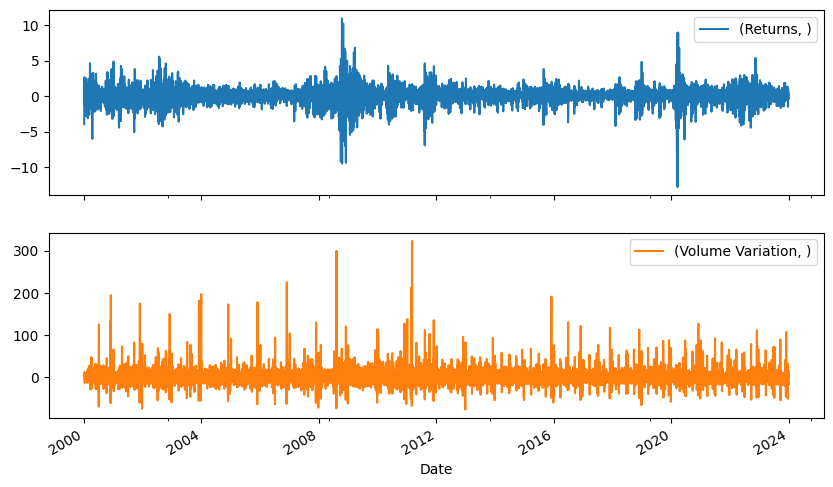

In [3]:
sp500[['Returns','Volume Variation']].plot(subplots=True, figsize=(10, 6))

<Axes: xlabel='Volume Variation', ylabel='Squared Returns'>

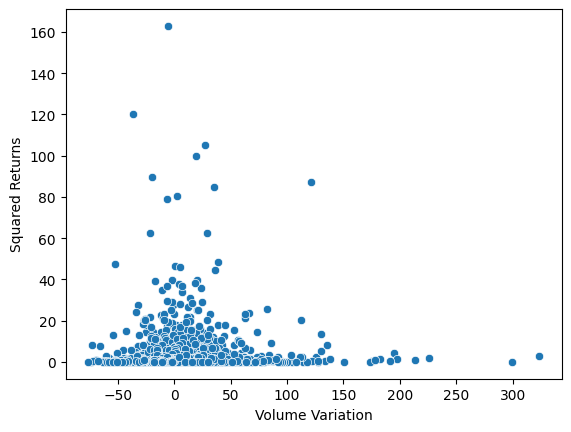

In [4]:
sns.scatterplot(sp500,x='Volume Variation',y='Squared Returns')

## Model Training
We will propose try to fit a $MS-ARCHX(d=2,q=1)$ model with exogeneous variable $X$ the Volume Daily Relative Variation

  0%|          | 0/1000 [00:00<?, ?it/s]/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  fx = wrapped_fun(x)
  0%|          | 1/1000 [00:03<1:03:06,  3.79s/it]/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  fx = wrapped_fun(x)
  0%|          | 2/1000 [00:04<32:12,  1.94s/it]  /Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  fx = wrapped_fun(x)
  0%|          | 3/1000 [00:05<22:52,  1.38s/it]/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning: Value

mu of dimension 2: will depend on delta


  0%|          | 0/1000 [00:00<?, ?it/s]/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  fx = wrapped_fun(x)
  0%|          | 1/1000 [00:02<36:52,  2.21s/it]/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  fx = wrapped_fun(x)
  0%|          | 2/1000 [00:02<20:20,  1.22s/it]/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  fx = wrapped_fun(x)
  0%|          | 3/1000 [00:03<15:09,  1.10it/s]/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning: Values in

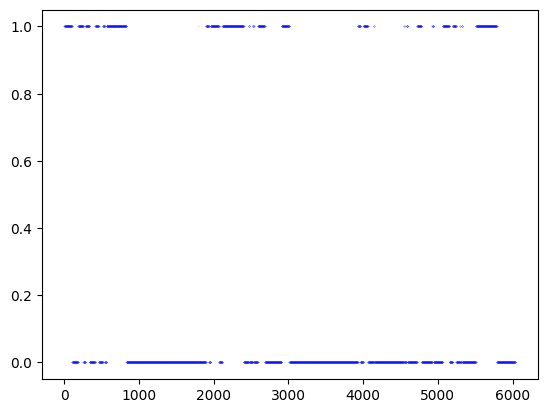

In [13]:
initial_params = {
    'exogen_additive':np.reshape(sp500['Volume Variation'],(-1,1)),\
    'exogen_transition':np.array(sp500['Volume Variation']),\
    }
target = np.array(sp500['Returns'])

d=2
q=1
niter_hmm = 1000
niter_MS = 1000

initial_params = get_initial_conditions(target,initial_params,d=2,q=1,niter=niter_hmm)
result = MS_EM_algorithm(target,initial_params,niter=niter_MS)

A constrained Version

  0%|          | 0/10 [00:00<?, ?it/s]

100%|██████████| 10/10 [00:01<00:00,  6.36it/s]


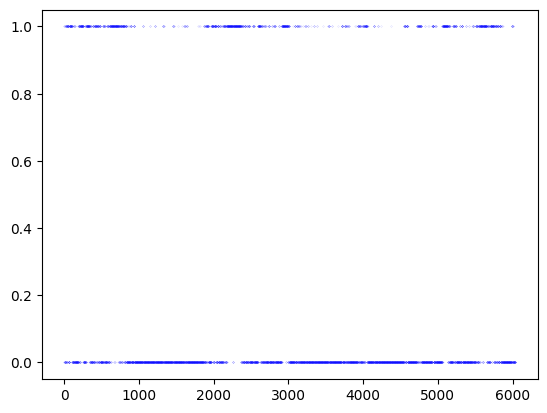

In [60]:
initial_params = {}
target = np.array(sp500['Returns'])

d=2
q=1
niter_hmm = 10
niter_MS = 10

initial_params = get_initial_conditions(target,initial_params,d=2,q=0,niter=niter_hmm)
result_constrained = MS_EM_algorithm(target,initial_params,niter=niter_MS)

In [22]:
result_constrained[niter_MS]

{'P': array([[0.99012607, 0.00987393],
        [0.01861306, 0.98138694]]),
 'omega': array([0.4592393 , 2.80751822]),
 'alpha': array([[0.02990793, 0.17322247]]),
 'pi_0': array([1.e-10, 1.e+00]),
 'log-likelihood': -8566.907125806505}

In [23]:
result[niter_MS]

{'P': array([[0.99048797, 0.00951203],
        [0.02237373, 0.97762627]]),
 'beta': array([[-0.0039176 ,  0.0039176 ],
        [ 0.00064134, -0.00064134]]),
 'omega': array([0.50556516, 3.80767318]),
 'alpha': array([[0.01342463, 0.        ]]),
 'mu': array([[0., 0.]]),
 'pi_0': array([1.e-10, 1.e+00]),
 'log-likelihood': -8626.067303800943}

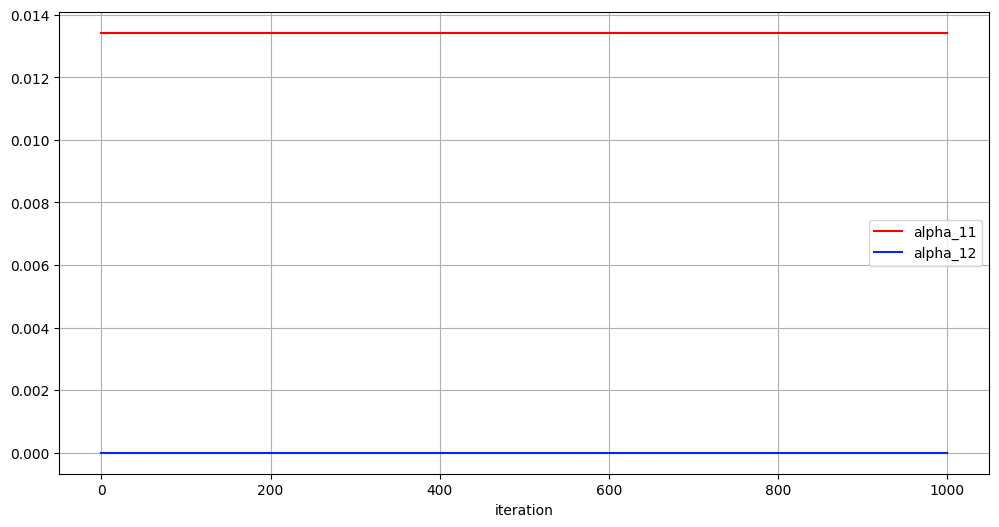

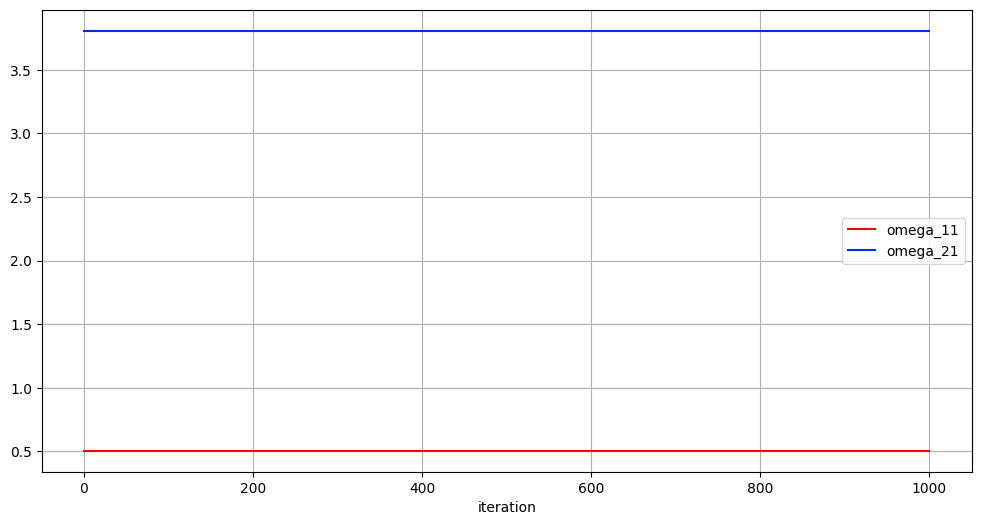

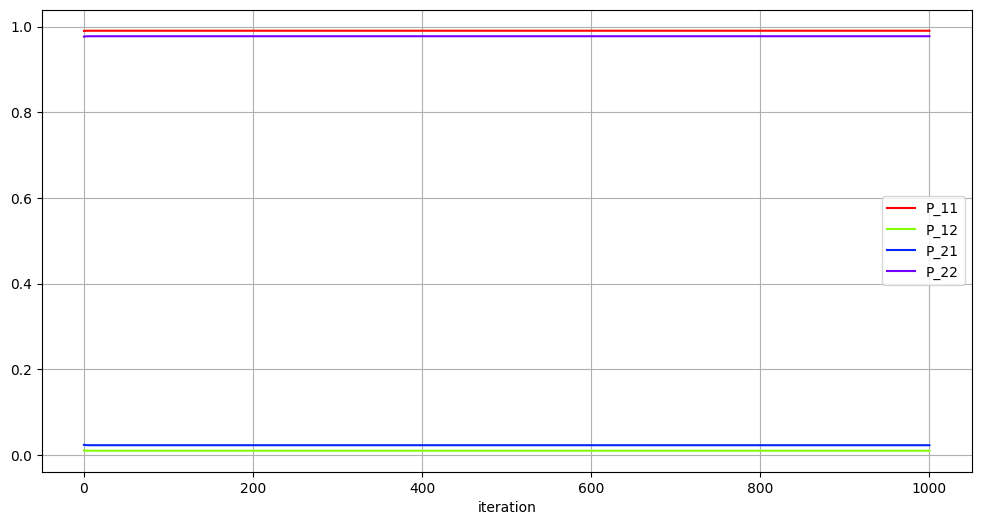

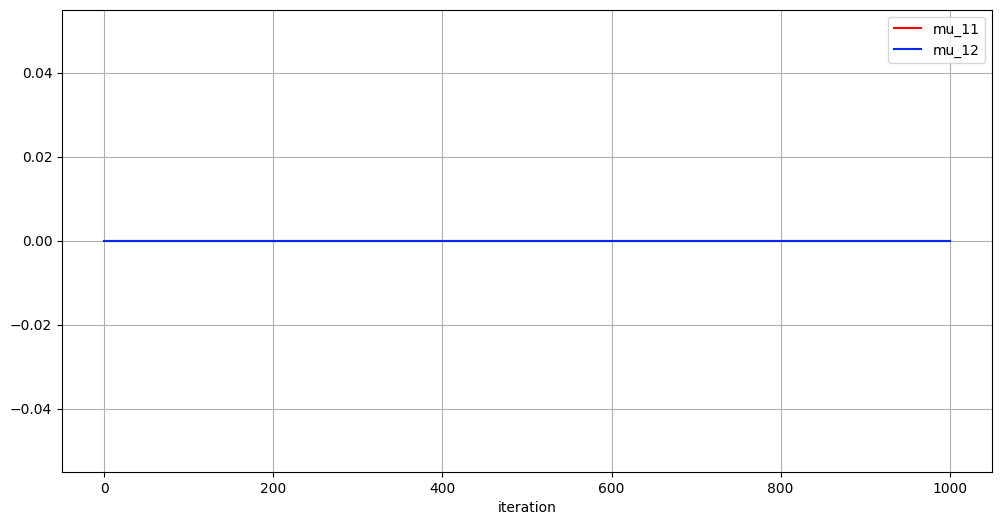

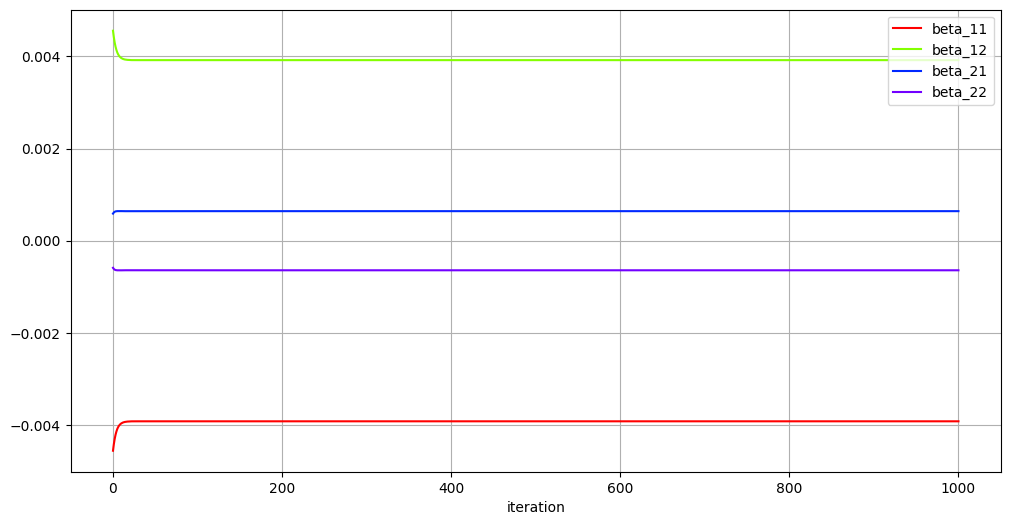

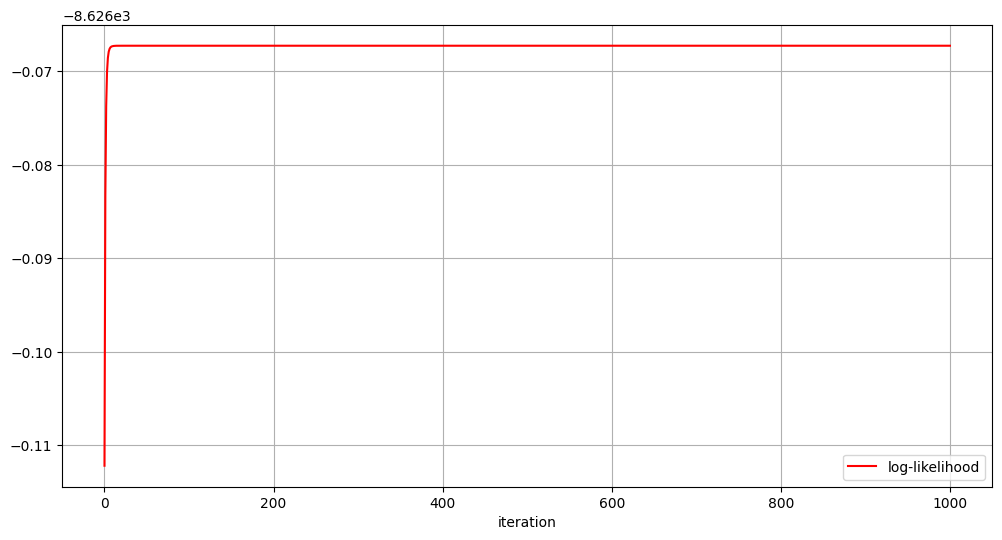

In [25]:
df = copy(result)
df[0] = {key:value for key,value in df[0].items() if key not in ['exogen_transition','mu_depends_on_delta','exogen_additive']}
#result_exogen[0].pop('mu_depends_on_delta')
df_exo = convert_dict_to_dataframe(df)

start = 'alpha'
cols = [col for col in df_exo.columns if col.startswith(start)]
colors = generate_colors(len(cols))
ax = df_exo.plot(y=cols,figsize=(12,6),grid=True,color=colors)
plt.legend()

start = 'omega'
cols = [col for col in df_exo.columns if col.startswith(start)]
colors = generate_colors(len(cols))
ax = df_exo.plot(y=cols,figsize=(12,6),grid=True,color=colors)
plt.legend()

start = 'P'
cols = [col for col in df_exo.columns if col.startswith(start)]
colors = generate_colors(len(cols))
ax = df_exo.plot(y=cols,figsize=(12,6),grid=True,color=colors)
plt.legend()

start = 'mu'
cols = [col for col in df_exo.columns if col.startswith(start)]
colors = generate_colors(len(cols))
ax = df_exo.plot(y=cols,figsize=(12,6),grid=True,color=colors)
plt.legend()

start = 'beta'
cols = [col for col in df_exo.columns if col.startswith(start)]
colors = generate_colors(len(cols))
ax = df_exo.plot(y=cols,figsize=(12,6),grid=True,color=colors)
plt.legend()

start = 'log-likelihood'
cols = [col for col in df_exo.columns if col.startswith(start)]
colors = generate_colors(len(cols))
ax = df_exo.plot(y=cols,figsize=(12,6),grid=True,color=colors)
plt.legend()

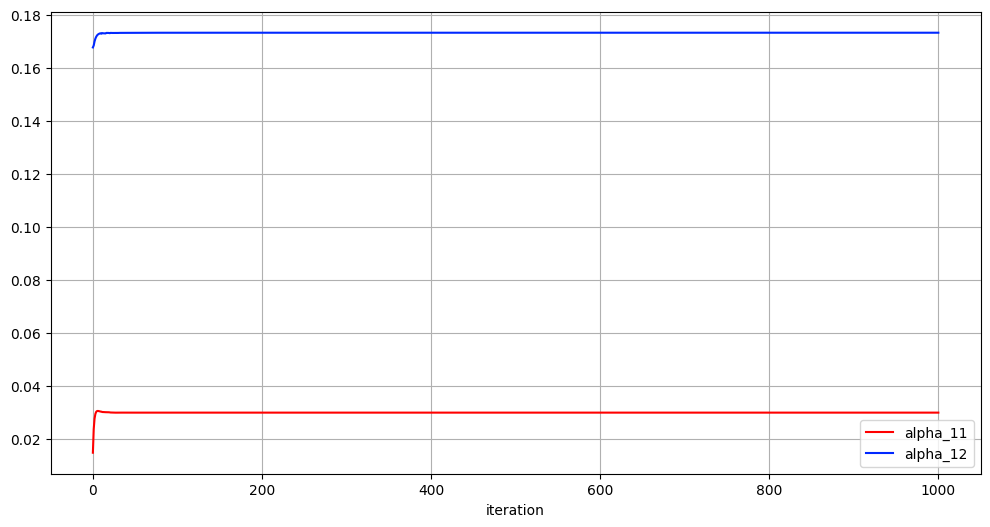

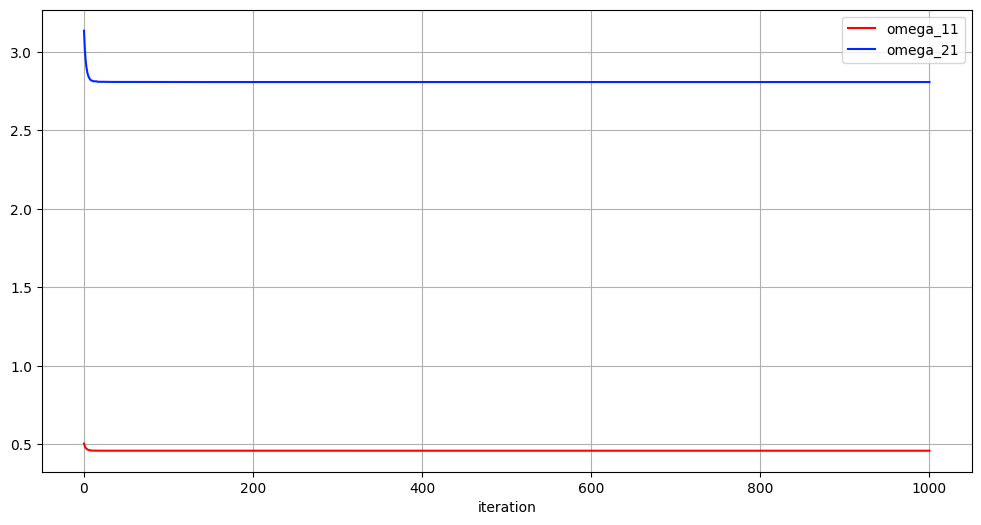

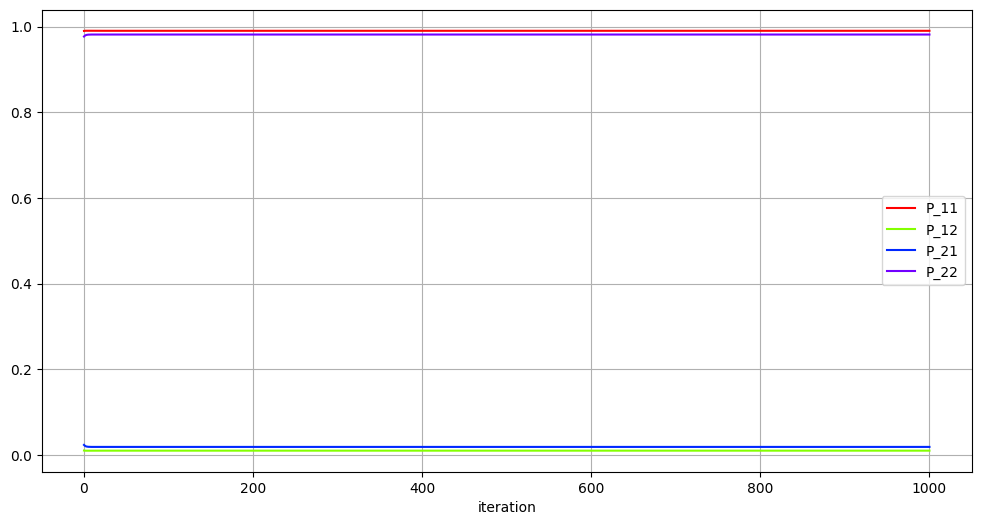

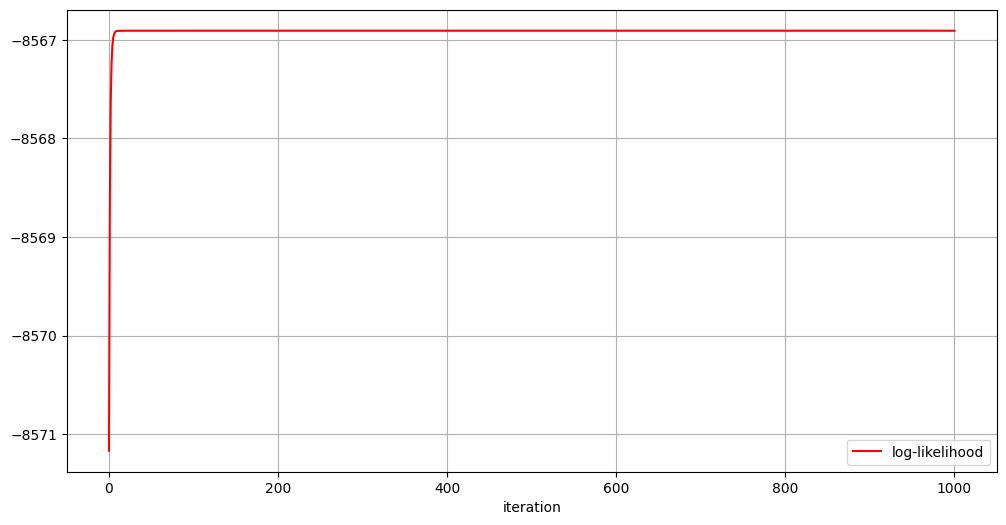

In [27]:
df = copy(result_constrained)
df[0] = {key:value for key,value in df[0].items() if key not in ['exogen_transition','mu_depends_on_delta','exogen_additive']}
#result_exogen[0].pop('mu_depends_on_delta')
df_exo = convert_dict_to_dataframe(df)

start = 'alpha'
cols = [col for col in df_exo.columns if col.startswith(start)]
colors = generate_colors(len(cols))
ax = df_exo.plot(y=cols,figsize=(12,6),grid=True,color=colors)
plt.legend()

start = 'omega'
cols = [col for col in df_exo.columns if col.startswith(start)]
colors = generate_colors(len(cols))
ax = df_exo.plot(y=cols,figsize=(12,6),grid=True,color=colors)
plt.legend()

start = 'P'
cols = [col for col in df_exo.columns if col.startswith(start)]
colors = generate_colors(len(cols))
ax = df_exo.plot(y=cols,figsize=(12,6),grid=True,color=colors)
plt.legend()

start = 'log-likelihood'
cols = [col for col in df_exo.columns if col.startswith(start)]
colors = generate_colors(len(cols))
ax = df_exo.plot(y=cols,figsize=(12,6),grid=True,color=colors)
plt.legend()

In [28]:
result_constrained[niter_MS]

{'P': array([[0.99012607, 0.00987393],
        [0.01861306, 0.98138694]]),
 'omega': array([0.4592393 , 2.80751822]),
 'alpha': array([[0.02990793, 0.17322247]]),
 'pi_0': array([1.e-10, 1.e+00]),
 'log-likelihood': -8566.907125806505}

In [16]:
result[niter_MS]

{'P': array([[0.99048797, 0.00951203],
        [0.02237373, 0.97762627]]),
 'beta': array([[-0.0039176 ,  0.0039176 ],
        [ 0.00064134, -0.00064134]]),
 'omega': array([0.50556516, 3.80767318]),
 'alpha': array([[0.01342463, 0.        ]]),
 'mu': array([[0., 0.]]),
 'pi_0': array([1.e-10, 1.e+00]),
 'log-likelihood': -8626.067303800943}

Starting from calibrated MS_ARCH model

In [34]:
new_initial_params = deepcopy(result_constrained[niter_MS])
new_initial_params['exogen_transition'] = np.array(sp500['Volume Variation'])
new_initial_params['exogen_additive'] = np.reshape(sp500['Volume Variation'],(-1,1))
new_initial_params['mu'] = np.array([[0,0]])
new_initial_params['beta'] = np.array([[0,0],[0,0]])

In [45]:
result2 = MS_EM_algorithm(target,new_initial_params,niter=niter_MS)

mu of dimension 2: will depend on delta


  0%|          | 0/1000 [00:00<?, ?it/s]

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  fx = wrapped_fun(x)
  0%|          | 2/1000 [00:02<21:18,  1.28s/it]/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  fx = wrapped_fun(x)
  0%|          | 3/1000 [00:03<16:32,  1.00it/s]/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  fx = wrapped_fun(x)
  0%|          | 4/1000 [00:04<14:12,  1.17it/s]/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning: Values in x were outside bounds during a minimize

In [47]:
result_constrained[niter_MS]

{'P': array([[0.99012607, 0.00987393],
        [0.01861306, 0.98138694]]),
 'omega': array([0.4592393 , 2.80751822]),
 'alpha': array([[0.02990793, 0.17322247]]),
 'pi_0': array([1.e-10, 1.e+00]),
 'log-likelihood': -8566.907125806505}

In [48]:
result2[niter_MS]

{'P': array([[0.99082579, 0.00917421],
        [0.01883097, 0.98116903]]),
 'beta': array([[-0.0076492 ,  0.0076492 ],
        [ 0.00058692, -0.00058692]]),
 'omega': array([0.4592393 , 2.80751822]),
 'alpha': array([[0.02990793, 0.17322247]]),
 'mu': array([[0., 0.]]),
 'pi_0': array([1.e-10, 1.e+00]),
 'log-likelihood': -8566.201975011627}

## PIT TEST
Conditionné au passé, chaque observation suit un mélange de lois normales centrées de variances $\sigma(i)^2$ et de poids $P(\Delta_t=i|X_1,..,X_{t-1},\epsilon_1,..,\epsilon_{t-1})$.\
Ainsi, la cdf de $\epsilon_t$ est donnée par $F(\epsilon_t) = \sum_{i=1}^dF(\epsilon_t|\Delta_t=i)P(\Delta_t=i|X_1,,..,X_{t-1},\epsilon_1,..,\epsilon_{t-1})$

In [282]:
def get_PIT_residuals(eps,params):
    n = len(eps)
    d = len(params['P'])
    pi = MS_hamilton_filter(eps,params,backward_pass=False)
    sigmas = get_sigma(eps,np.arange(len(eps)),params.get('omega'),params.get('alpha'),params.get('exogen_additive'),params.get('mu'))
    residuals = [sum([norm.cdf(eps[t],scale=sigmas[t,i])*pi[t+1,t,i] for i in range(d)]) for t in range(1,n)]
    return residuals

Text(0.5, 1.0, 'KS Test p-value: 1.4709273410183758e-18')

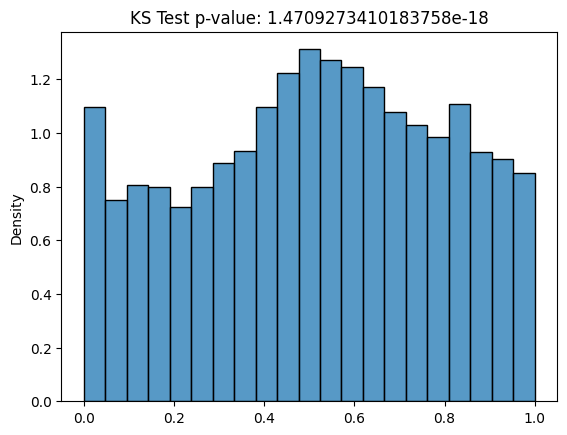

In [283]:
PIT_residuals = get_PIT_residuals(sp500['Returns'].to_numpy()*100,u__[50])

sns.histplot(PIT_residuals,stat='density')
plt.title(f'KS Test p-value: {round(stats.kstest(PIT_residuals,stats.uniform.cdf).pvalue,100)}')

Text(0.5, 1.0, 'KS Test p-value: 2.0658496569720531e-13')

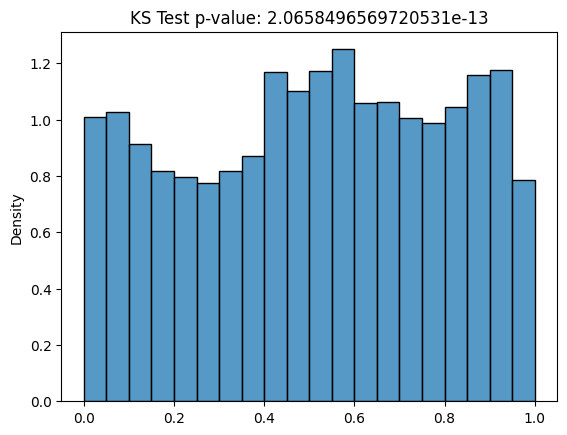

In [187]:
PIT_residuals = get_PIT_residuals(sp500['Returns'].to_numpy()*100,u2[500])

sns.histplot(PIT_residuals,stat='density')
plt.title(f'KS Test p-value: {round(stats.kstest(PIT_residuals,stats.uniform.cdf).pvalue,100)}')